In [1]:
import glob, copy
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from skimage import measure, morphology

from scipy import ndimage

In [2]:
def getLabel(original, mask_full):
    crop_region = np.zeros_like(original)
    crop_region[120:-10,30:390] = 1
    original = original * crop_region
    footprint = np.array([5,3])
    w_tophat = ndimage.white_tophat(original, footprint)
    w_tophat[w_tophat<0] = 0
    
    thresh = w_tophat > np.percentile(w_tophat,94,axis=0)
    temp3 = thresh > mask_full
    temp3 = morphology.remove_small_objects(temp3, min_size=5, connectivity=1)
    
    ycord, xcord = np.nonzero(temp3)
    X_points = np.vstack([xcord,ycord]).T
    
    label_img, num = measure.label(temp3, return_num=True)

    clustering = AgglomerativeClustering(linkage='single', n_clusters= int(num * 0.75))
    clustering.fit(X_points)
    
    cluster_labels = clustering.labels_
    cluster_labels += 1
    
    unique_labels = np.unique(cluster_labels)
    cluster_size = np.array([np.sum( cluster_labels == label) for label in unique_labels])
        
    return xcord, ycord, cluster_labels

In [3]:
outdir = 'handpick/'
trace_files = glob.glob1(outdir,'*.npy') 

orgdir = 'npy/'
# original_files = glob.glob1(orgdir,'*.npy') 

In [6]:
# file_idx = 50
for file_idx in range(len(trace_files)):
    picked = np.load(outdir+trace_files[file_idx],allow_pickle=True)[()]
    trace = picked['mask_full']
    cleaned = np.load(orgdir+trace_files[file_idx],allow_pickle=True)[()]
    original = cleaned['original']

    Xcord, Ycord, Label = getLabel(original, trace)
    noise_list = []
    for l in np.unique(Label):
        noise_list.append([Xcord[Label==l],Ycord[Label==l]])
    np.save('../Hand_pick_noise/'+trace_files[file_idx], {'noise_list': noise_list, 'mask_full': trace})
    # break

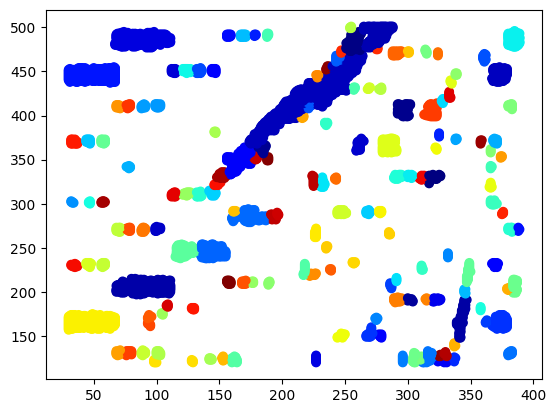

In [7]:
ax = plt.subplot()
im = ax.scatter(Xcord, Ycord, c= Label,cmap='jet')